In [296]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.decomposition import PCA


In [297]:
df=pd.read_csv("5-sales_data_sample.csv",encoding="latin1")
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

In [298]:
feature=["QUANTITYORDERED","MSRP","SALES","PRICEEACH"]
df=df.dropna(subset=feature)

In [299]:
sc=StandardScaler()
x=df[feature]


In [300]:
x_scale=sc.fit_transform(x)

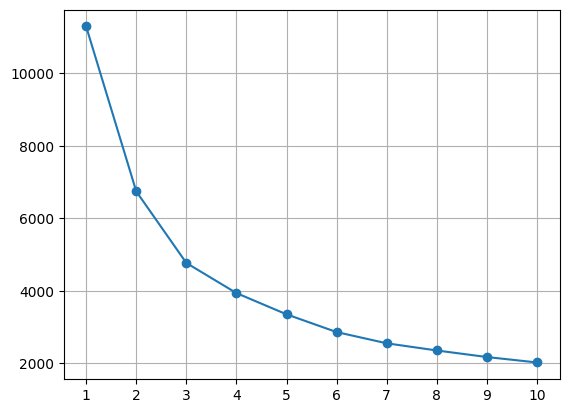

In [308]:
wscc=[]
for i in range(1,11):
    km=KMeans(n_clusters=i,random_state=42,n_init=10)
    km.fit_predict(x_scale)
    wscc.append(km.inertia_)
plt.plot(range(1,11),wscc,marker="o")
plt.grid(True)
plt.xticks(range(1,11))
plt.show()

In [309]:
km=KMeans(n_clusters=3,random_state=42,n_init=10)
df["kmean"]=km.fit_predict(x_scale)
print(df["kmean"].value_counts())


kmean
2    996
0    975
1    852
Name: count, dtype: int64


In [310]:
hm=AgglomerativeClustering(n_clusters=3)
df["hmean"]=hm.fit_predict(x_scale)
print(df["hmean"].value_counts())

hmean
0    1204
1     934
2     685
Name: count, dtype: int64


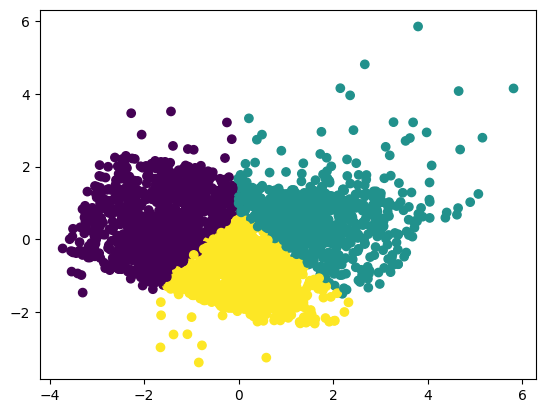

In [314]:
pca=PCA(n_components=3).fit_transform(x_scale)

plt.scatter(pca[:,0],pca[:,1],c=df["kmean"])

plt.show()

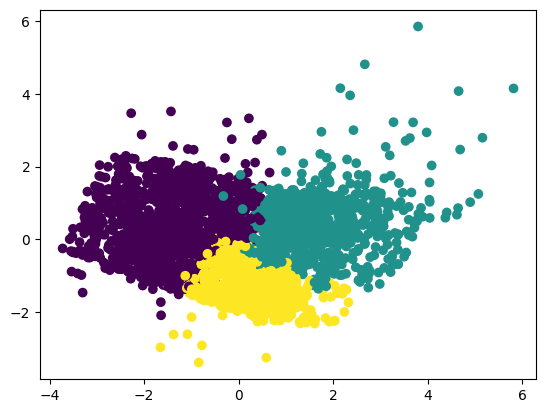

In [315]:
pca=PCA(n_components=3).fit_transform(x_scale)

plt.scatter(pca[:,0],pca[:,1],c=df["hmean"])

plt.show()

In [316]:
print(df.groupby("kmean")[feature].mean())

       QUANTITYORDERED        MSRP        SALES  PRICEEACH
kmean                                                     
0            35.208205   64.145641  2101.076482  59.551169
1            43.723005  127.893192  5720.080669  97.479261
2            27.597390  113.266064  3123.062801  95.435090


In [317]:
print(df.groupby("hmean")[feature].mean())

       QUANTITYORDERED        MSRP        SALES  PRICEEACH
hmean                                                     
0            35.479236   70.546512  2273.005623  63.746694
1            41.710921  127.048180  5575.633972  99.286777
2            25.389781  117.837956  3048.595547  97.347737
